# ![](https://ga-dash.s3.amazonaws.com/production/assets/logo-9f88ae6c9c3871690e33280fcf557f33.png) 4.03 - Generalized Linear Models
#### Creator: Matt Brems (DC) h/t Timothy Book.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

import matplotlib.pyplot as plt
%matplotlib inline

/Users/mattbrems/anaconda3/lib/python3.5/site-packages/statsmodels/compat/pandas.py:56: FutureWarning: The pandas.core.datetools module is deprecated and will be removed in a future version. Please use the pandas.tseries module instead.
  from pandas.core import datetools


## Generalized Linear Models (GLMs)
**Generalized linear models** describes a class of models that take the linear model (think linear regression) and generalizes the linear model beyond the assumptions of the linear regression model we discussed last week.

## The `statsmodels` API
In what follows, we will explore the statsmodels API, which is a one-stop-shop for most things GLM in Python.  Documentation and examples can be found [here](http://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html#statsmodels.genmod.generalized_linear_model.GLM).

## Logistic Regression

**When do we use it?** When we want to model something on the $\{0,1\}$ range... like whether or not somebody will develop a disease.

### The Data
The data used from this example come from one of UCLA's amazing IDRE modules (for R).  The module can be found [here](https://stats.idre.ucla.edu/r/dae/logit-regression/).

**Data Description:** _A researcher is interested in how variables, such as GRE (Graduate Record Exam scores), GPA (grade point average) and prestige of the undergraduate institution, effect admission into graduate school. The response variable, admit/don’t admit, is a binary variable._

In [2]:
grad = pd.read_csv("https://stats.idre.ucla.edu/stat/data/binary.csv")

# Let's do some EDA!
print(grad.shape)
grad.head()

(400, 4)


,admit,gre,gpa,rank
0,0,380,3.61,3
1,1,660,3.67,3
2,1,800,4.00,1
3,1,640,3.19,4
4,0,520,2.93,4


In [3]:
grad.describe()

,admit,gre,gpa,rank
count,400.000000,400.000000,400.000000,400.00000
mean,0.317500,587.700000,3.389900,2.48500
std,0.466087,115.516536,0.380567,0.94446
min,0.000000,220.000000,2.260000,1.00000
25%,0.000000,520.000000,3.130000,2.00000
50%,0.000000,580.000000,3.395000,2.00000
75%,1.000000,660.000000,3.670000,3.00000
max,1.000000,800.000000,4.000000,4.00000


In [4]:
grad.admit.value_counts()

0    273
1    127
Name: admit, dtype: int64

array([<matplotlib.axes._subplots.AxesSubplot object at 0x1160d0d30>,
       <matplotlib.axes._subplots.AxesSubplot object at 0x1161b1400>], dtype=object)

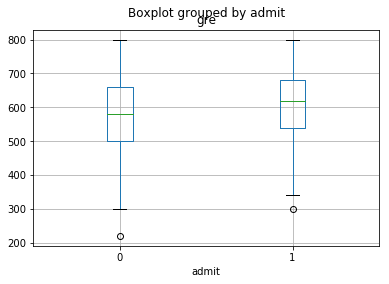

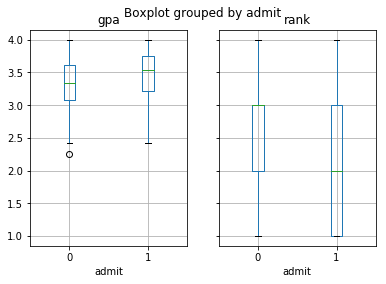

In [5]:
grad.boxplot('gre', by = 'admit')
grad.boxplot(['gpa', 'rank'], by = 'admit')

In [6]:
# Now, let's build our GLM
indep_vars = ['gre', 'gpa', 'rank']
x_mat = sm.add_constant(grad[indep_vars])
y_vec = grad.admit
glm_logit = sm.GLM(y_vec, 
                   x_mat,
                   sm.families.Binomial(sm.families.links.logit)).fit()

In [7]:
glm_logit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  admit   No. Observations:                  400
Model:                            GLM   Df Residuals:                      396
Model Family:                Binomial   Df Model:                            3
Link Function:                  logit   Scale:                             1.0
Method:                          IRLS   Log-Likelihood:                -229.72
Date:                Tue, 06 Feb 2018   Deviance:                       459.44
Time:                        11:11:05   Pearson chi2:                     399.
No. Iterations:                     4                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.4495      1.133     -3.045      0.002      -5.670      -1.229
gre            0.0023      0.001      2.101      0.036       0.000       0.004
gpa            0.7770      0.327      2.373      0.018       0.135       1.419
rank          -0.5600      0.127     -4.405      0.000      -0.809      -0.311
==============================================================================
"""

**Check:** How would I interpret the coefficient for `rank`?

In [8]:
import math
math.exp(-0.5600)

0.5712090638488149

**Interpretation:** As the rank of my undergraduate institution increases by 1, I am 57% as likely to be admitted to graduate school.

**Check:** If I scored 100 points better on my GRE, how would that affect my odds of acceptance?

In [9]:
math.exp(100*0.0023)

1.2586000099294778

**Interpretation:** As my GRE score increases by 100 points, I am 126% as likely to be admitted to graduate school.

**Interpretation 2:** As my GRE score increases by 100 points, I am 26% more likely to be admitted to graduate school.

**Note:**
1. `IRLS` and `No. Iterations.`
    - $\mathbf{\hat{\beta}}_1 = (X^TW_1X)^{-1}(X^TW_1y)$
    - $\mathbf{\hat{\beta}}_2 = (X^TW_2X)^{-1}(X^TW_2y)$
    - $\mathbf{\hat{\beta}}_3 = (X^TW_3X)^{-1}(X^TW_3y)$
    - $\vdots$
    - Once the difference between $\mathbf{\hat{\beta}}_i$ and $\mathbf{\hat{\beta}}_{i+1}$ is small enough, the algorithm has "converged" and we have our coefficient estimates for $\mathbf{\beta}$.
    - The maximum number of iterations for GLMs is 100. If `No. Iterations` is 100, that means the algorithm probably didn't converge and that the $\mathbf{\hat{\beta}}$ are still changing. Therefore, **your output is unreliable - DO NOT USE IT**.
2. Does this model perform well?

In [10]:
# Next, let's see if we can safely reduce our model
reduced_vars = ['gre', 'gpa']
x_reduced = sm.add_constant(grad[reduced_vars])
glm_reduced = sm.GLM(y_vec,
                    x_reduced,
                    sm.families.Binomial(sm.families.links.logit)).fit()
glm_reduced.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  admit   No. Observations:                  400
Model:                            GLM   Df Residuals:                      397
Model Family:                Binomial   Df Model:                            2
Link Function:                  logit   Scale:                             1.0
Method:                          IRLS   Log-Likelihood:                -240.17
Date:                Tue, 06 Feb 2018   Deviance:                       480.34
Time:                        11:23:06   Pearson chi2:                     398.
No. Iterations:                     4                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.9494      1.075     -4.604      0.000      -7.057      -2.842
gre            0.0027      0.001      2.544      0.011       0.001       0.005
gpa            0.7547      0.320      2.361      0.018       0.128       1.381
==============================================================================
"""

### Analysis of Deviance

We've spoken briefly about deviance before as a generalization of the sums of squares of error for generalized linear models.

Suppose we have two models:

$$
\begin{eqnarray*}
Y_{full} &=& \beta_0 + \beta_1X_1 + \cdots + \beta_kX_k + \cdots + \beta_pX_p + \varepsilon \\
Y_{reduced} &=& \beta_0 + \beta_1X_1 + \cdots + \beta_kX_k + \varepsilon
\end{eqnarray*}
$$

We say that $Y_{reduced}$ is nested in $Y_{full}$, because the reduced model could "fit inside" the full. (You can learn more about nested linear regression models [here](http://people.reed.edu/~jones/Courses/P24.pdf), although the ideas approximately hold for generalized linear models as well.)

When we have one model nested inside the other, there is a statistical test to see if adding new variables are worth it. (Think about it like looking at the difference in mean squared error or $R^2$ by adding a variable, but getting a $p$-value quantifying whether or not it's worth it!)

We calculate the **deviance** of the reduced model and subtract the **deviance** of the full model from it. This difference in deviance follows a [chi-squared distribution](https://en.wikipedia.org/wiki/Chi-squared_distribution) with $p-k$ degrees of freedom. (Note that $p-k$ indicates how many variables we took out of our full model to get to the reduced model!)

**This comparison only works with nested models! Do not use if your models are not nested!**

In [12]:
# Test model differences
from scipy.stats import chi2

D = glm_reduced.deviance - glm_logit.deviance
print('Difference in Deviance: ', D)
pval = 1 - chi2.cdf(D, df = 1)
print('p-value of test of difference: ', pval) # What can we conclude here?

Difference in Deviance:  20.9022166536
p-value of test of difference:  4.83334960077e-06


$H_0:$ reduced model is better
$H_A:$ reduced model is not better

Because $p < \alpha$, we reject $H_0$ and conclude that the reduced model is not better.

## Poisson Regression

**When do we use it?** When we want to model something on the $\{0,1,2,\ldots\}$ range... like number of objects sold or nunber of awards earned!

#### Data
We'll again rely on UCLA's IDRE module.  This one can be found [here](https://stats.idre.ucla.edu/r/dae/poisson-regression/).

#### Data Description
_The number of awards earned by students at one high school. Predictors of the number of awards earned include the type of program in which the student was enrolled (e.g., vocational, general or academic) and the score on their final exam in math._

In [13]:
award = pd.read_csv("https://stats.idre.ucla.edu/stat/data/poisson_sim.csv")

# Let's do some EDA:
award.head()

,id,num_awards,prog,math
0,45,0,3,41
1,108,0,1,41
2,15,0,3,44
3,67,0,3,42
4,153,0,3,40


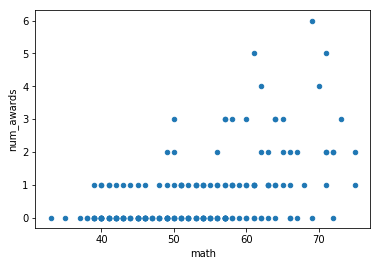

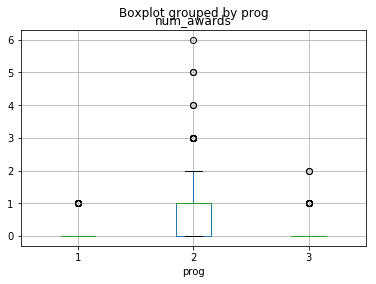

In [14]:
award.plot('math', 'num_awards', kind = 'scatter')
award.boxplot('num_awards', by = 'prog')

In [15]:
# Notice that prog is actually a categorical variable - I am aware of this.
# I'm going to suspsend that knowledge for the sake of example.
poi_vars = ['prog', 'math']
x_poi = sm.add_constant(award[poi_vars])
y_poi = award.num_awards

glm_poi = sm.GLM(y_poi,
                 x_poi,
                 family = sm.families.Poisson()).fit()
glm_poi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:             num_awards   No. Observations:                  200
Model:                            GLM   Df Residuals:                      197
Model Family:                 Poisson   Df Model:                            2
Link Function:                    log   Scale:                             1.0
Method:                          IRLS   Log-Likelihood:                -189.75
Date:                Tue, 06 Feb 2018   Deviance:                       203.45
Time:                        11:35:10   Pearson chi2:                     227.
No. Iterations:                     5                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.5781      0.677     -8.242      0.000      -6.905      -4.252
prog           0.1233      0.163      0.755      0.450      -0.197       0.443
math           0.0861      0.010      8.984      0.000       0.067       0.105
==============================================================================
"""

**Interpretation**: For a one-unit increase in `math`, I expect to win $e^{0.0861} \approx 1.09$ times as many awards.

In [16]:
math.exp(0.0861)

1.0899153143871725

In [17]:
# Interesting - it looks like prog is pretty insignificant.
# Let's try removing it and seeing what happens.
x_poi_red = sm.add_constant(award.math)

glm_poi_red = sm.GLM(y_poi,
                     x_poi_red,
                     family = sm.families.Poisson()).fit()
glm_poi_red.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:             num_awards   No. Observations:                  200
Model:                            GLM   Df Residuals:                      198
Model Family:                 Poisson   Df Model:                            1
Link Function:                    log   Scale:                             1.0
Method:                          IRLS   Log-Likelihood:                -190.04
Date:                Tue, 06 Feb 2018   Deviance:                       204.02
Time:                        11:36:55   Pearson chi2:                     229.
No. Iterations:                     5                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.3335      0.591     -9.021      0.000      -6.492      -4.175
math           0.0862      0.010      8.902      0.000       0.067       0.105
==============================================================================
"""

In [18]:
# Test model difference:
D_poi = glm_poi_red.deviance - glm_poi.deviance
print('Difference in Deviance: ', D_poi)
pval_poi = 1 - chi2.cdf(D_poi, 1)
print('p-value of test of difference: ', pval_poi) # What does this mean?

Difference in Deviance:  0.570112255073
p-value of test of difference:  0.450214312658


## Gamma Regression

**When do we use it?** When we want to model something on the $[0,\infty)$ range... like time until some event occurs!

### The Data
The data used from this example come from a 1945 study about and is inspired by [Peter Craigmile's use](http://www.craigmile.com/peter/teaching/7430/notes/7_gamma_influence.pdf) of this example.

**Data Description:** _“Hurn, et al. (1945) published data on the clotting time of blood, giving clotting time in seconds for normal plasma diluted to nine different percentage concentrations with prothrombin-free plasma; clotting was induced by two lots of thromboplastin.” [McCullagh and Nelder](http://www.utstat.toronto.edu/~brunner/oldclass/2201s11/readings/glmbook.pdf)_

In [19]:
clot = pd.read_csv("./clotting.csv", index_col = "index")

In [20]:
clot.head()

,plasma_pct,clot_time,lot
index,,,
1,5,118,1
2,10,58,1
3,15,42,1
4,20,35,1
5,30,27,1


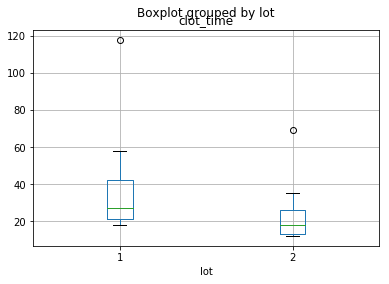

In [21]:
clot.boxplot('clot_time', by = 'lot')

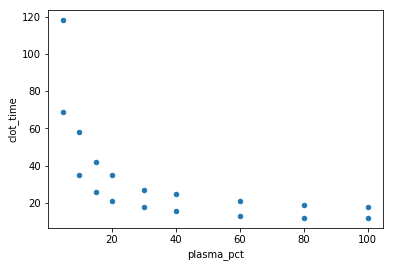

In [22]:
clot.plot('plasma_pct', 'clot_time', kind = 'scatter')

In [23]:
clot['plasma_pct_log10'] = np.log10(clot['plasma_pct'])

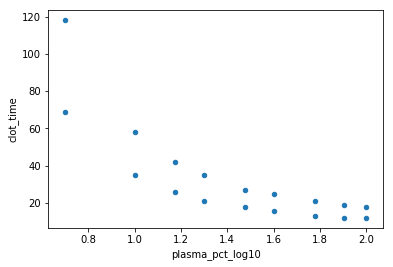

In [24]:
clot.plot('plasma_pct_log10', 'clot_time', kind = 'scatter')

In [25]:
clot['interaction'] = clot['plasma_pct_log10'] * clot['lot']

In [26]:
y_gam = clot['clot_time']
x_gam = sm.add_constant(clot[['plasma_pct_log10','lot','interaction']])

glm_gam = sm.GLM(y_gam,
                 x_gam,
                 family = sm.families.Gamma()).fit()
glm_gam.summary()

/Users/mattbrems/anaconda3/lib/python3.5/site-packages/statsmodels/genmod/generalized_linear_model.py:244: DomainWarning: The inverse_power link function does not respect the domain of the Gamma family.
  DomainWarning)


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              clot_time   No. Observations:                   18
Model:                            GLM   Df Residuals:                       14
Model Family:                   Gamma   Df Model:                            3
Link Function:          inverse_power   Scale:                0.00212969153597
Method:                          IRLS   Log-Likelihood:                -26.889
Date:                Tue, 06 Feb 2018   Deviance:                     0.029401
Time:                        11:41:25   Pearson chi2:                   0.0298
No. Iterations:                     5                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.0092      0.002     -4.089      0.000      -0.014      -0.005
plasma_pct_log10     0.0163      0.002      7.121      0.000       0.012       0.021
lot                 -0.0074      0.002     -4.383      0.000      -0.011      -0.004
interaction          0.0190      0.002     11.229      0.000       0.016       0.022
====================================================================================
"""

In [27]:
y_gam = clot['clot_time']
x_gam = sm.add_constant(clot[['plasma_pct_log10','lot','interaction']])

glm_gam_log = sm.GLM(y_gam,
                     x_gam,
                     family = sm.families.Gamma(link = sm.families.links.log)).fit()
glm_gam_log.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              clot_time   No. Observations:                   18
Model:                            GLM   Df Residuals:                       14
Model Family:                   Gamma   Df Model:                            3
Link Function:                    log   Scale:                 0.0237527980299
Method:                          IRLS   Log-Likelihood:                -48.371
Date:                Tue, 06 Feb 2018   Deviance:                      0.31576
Time:                        11:42:35   Pearson chi2:                    0.333
No. Iterations:                     6                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                6.0877      0.420     14.486      0.000       5.264       6.911
plasma_pct_log10    -1.4654      0.281     -5.211      0.000      -2.017      -0.914
lot                 -0.5845      0.266     -2.199      0.028      -1.105      -0.064
interaction          0.0794      0.178      0.446      0.655      -0.269       0.428
====================================================================================
"""

**Interpretation**: For a one-unit increase in `plasma_pct_log10`, I expect the blood will take $e^{-1.4654} \approx 23\%$ as much time to clot.

In [28]:
math.exp(-1.4654)

0.230985578764514